In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt

from spectrogram import iq_to_spectrogram
from anomalies import add_tone, add_chirp, add_pulse, add_comb, add_ofdm, add_fsk

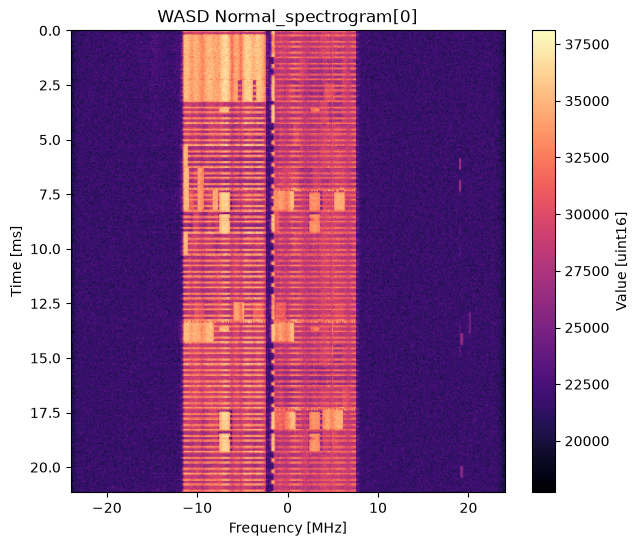

In [ ]:
spectrograms = np.memmap("data/wasd/Normal_spectrogram.npy", dtype=np.uint16, mode="r").reshape(-1, 400, 400)

plt.figure(figsize=(7, 6))
plt.imshow(spectrograms[0], cmap="magma", aspect="auto", extent=[-24, 24, 21.16, 0])
plt.xlabel("Frequency [MHz]")
plt.ylabel("Time [ms]")
plt.title("WASD Normal_spectrogram[0]")
plt.colorbar(label="Value [uint16]")
plt.show()

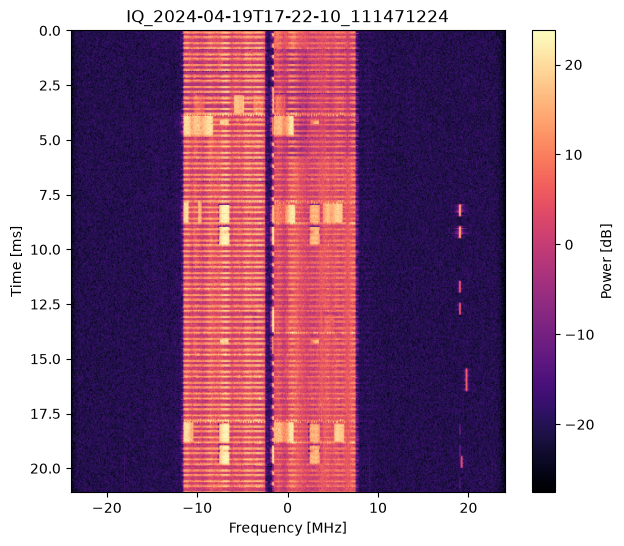

In [ ]:
name = "IQ_2024-04-19T17-22-10_111471224"
path = "data/iq/" + name
fs = json.load(open(path + ".json"))["sampling_frequency"]  # 61.44 MHz

raw = np.fromfile(path + ".bin", dtype=np.int32)
iq = raw[0::2] + 1j * raw[1::2]

sxx_db, duration_ms = iq_to_spectrogram(iq, fs)

plt.figure(figsize=(7, 6))
plt.imshow(sxx_db, cmap="magma", aspect="auto", extent=[-24, 24, duration_ms, 0],
           vmin=np.percentile(sxx_db, 1), vmax=np.percentile(sxx_db, 99.9))
plt.xlabel("Frequency [MHz]")
plt.ylabel("Time [ms]")
plt.title(name)
plt.colorbar(label="Power [dB]")
plt.show()

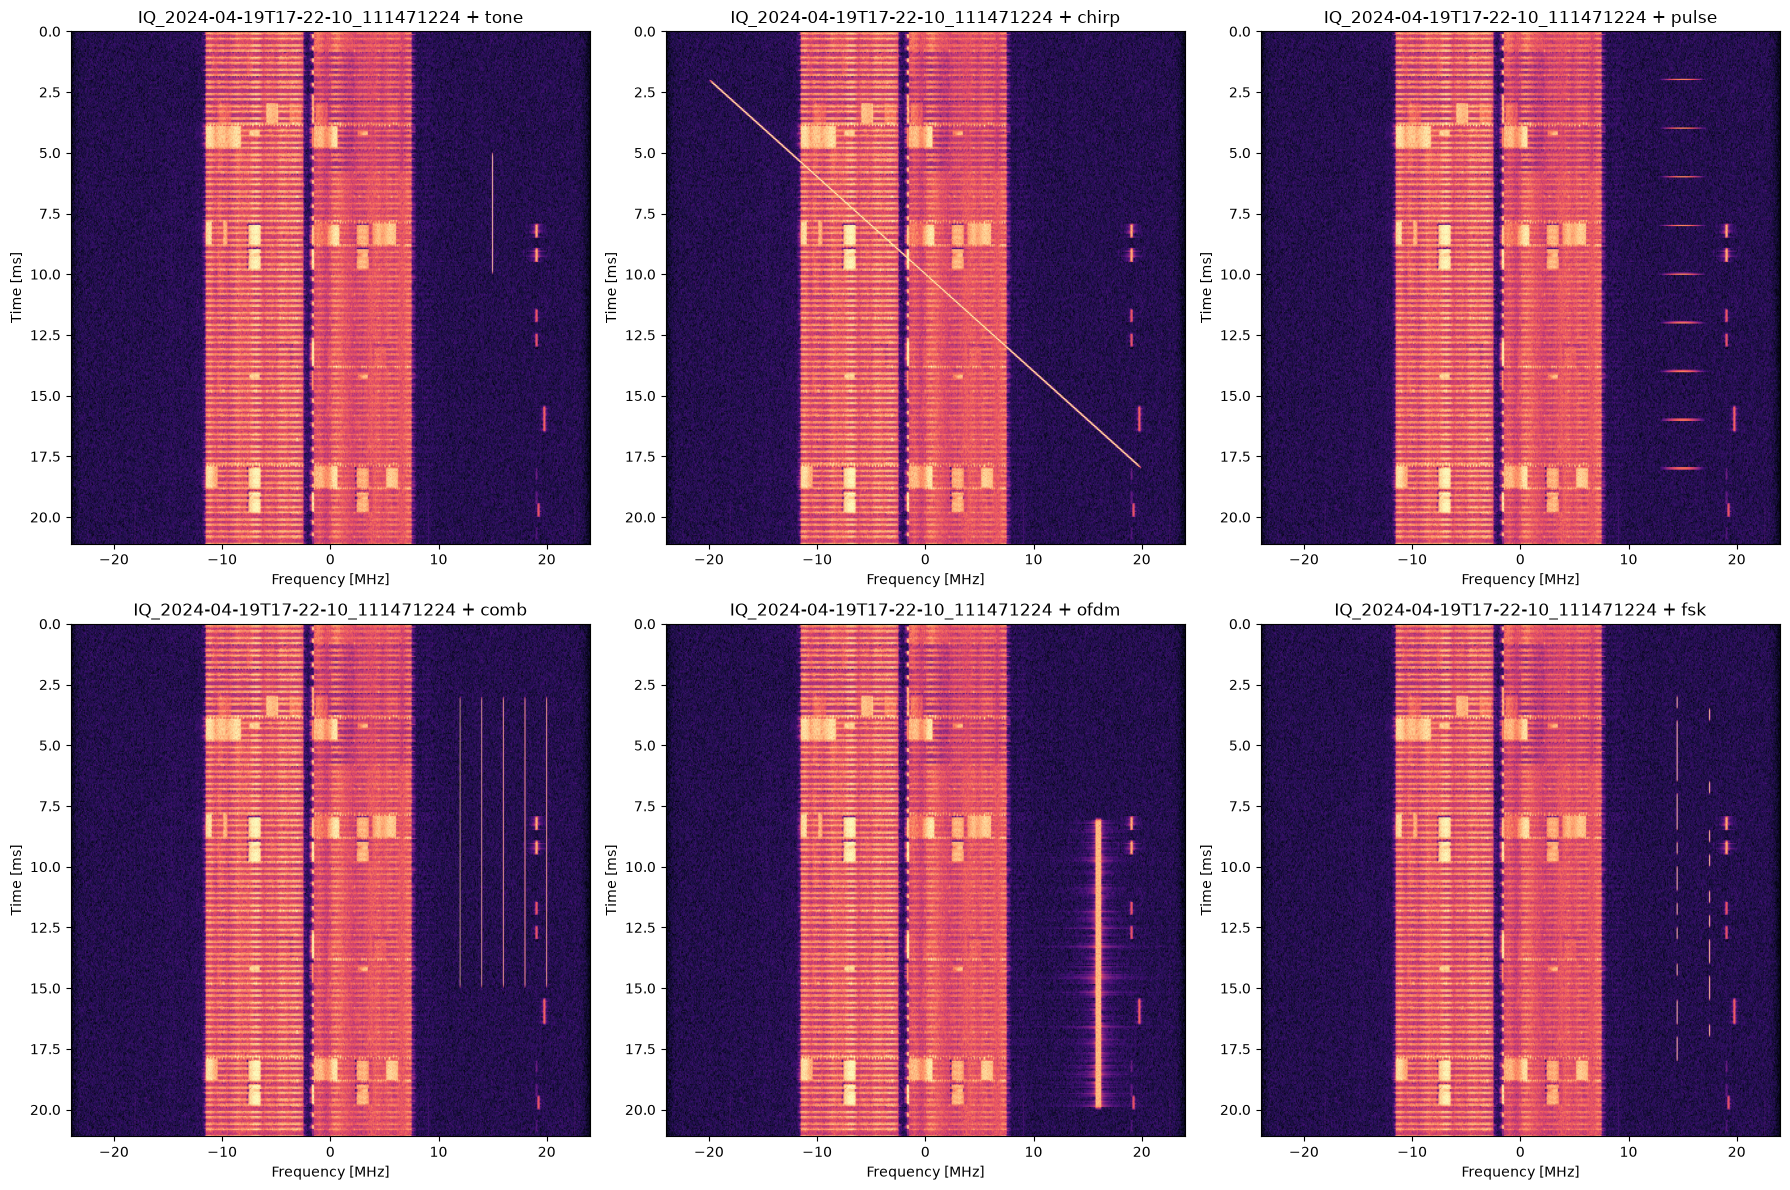

In [6]:
rng = np.random.default_rng(0)

examples = {
    "tone": add_tone(iq, fs, freq=15e6, start=5e-3, stop=10e-3, isr=-10),
    "chirp": add_chirp(iq, fs, f_start=-20e6, f_stop=20e6, start=2e-3, stop=18e-3, isr=-10),
    "pulse": add_pulse(iq, fs, freq=15e6, start=2e-3, stop=20e-3, isr=10),
    "comb": add_comb(iq, fs, f_first=12e6, spacing=2e6, n_tones=5, start=3e-3, stop=15e-3, isr=-10),
    "ofdm": add_ofdm(iq, fs, freq=16e6, bandwidth=5e5, start=8e-3, stop=20e-3, isr=-10, rng=rng),
    "fsk": add_fsk(iq, fs, freq=16e6, deviation=1.5e6, symbol_duration=0.5e-3,
                   start=3e-3, stop=18e-3, isr=-10, rng=rng),
}

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
for ax, (kind, iq_anomaly) in zip(axes.ravel(), examples.items()):
    sxx_db, duration_ms = iq_to_spectrogram(iq_anomaly, fs)
    ax.imshow(sxx_db, cmap="magma", aspect="auto", extent=[-24, 24, duration_ms, 0],
              vmin=np.percentile(sxx_db, 1), vmax=np.percentile(sxx_db, 99.9))
    ax.set_xlabel("Frequency [MHz]")
    ax.set_ylabel("Time [ms]")
    ax.set_title(name + " + " + kind)
plt.tight_layout()
plt.show()

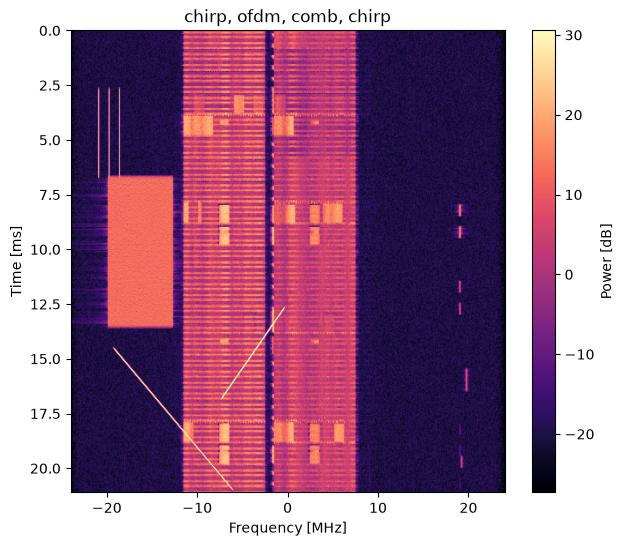

[{'type': 'chirp',
  'f_start': -249838.23102829605,
  'f_stop': -7448302.0147741735,
  'ramp': 0.0002,
  'start': 0.012610701084031206,
  'stop': 0.016907102537670048,
  'isr': 5.688080103226056},
 {'type': 'ofdm',
  'freq': -16287196.383583903,
  'bandwidth': 7190393.716172303,
  'subcarrier_spacing': 15000.0,
  'ramp': 0.0002,
  'start': 0.0066073096078034296,
  'stop': 0.013636663865208166,
  'isr': -1.8933419445461759},
 {'type': 'comb',
  'f_first': -20899655.294770706,
  'spacing': 1148855.271181337,
  'n_tones': 3,
  'ramp': 0.0002,
  'start': 0.002606547919864698,
  'stop': 0.006786958967656578,
  'isr': 3.7896383571246304},
 {'type': 'chirp',
  'f_start': -19363753.52903286,
  'f_stop': -5933349.10717939,
  'ramp': 0.0002,
  'start': 0.014457234453157986,
  'stop': 0.02104781100488285,
  'isr': -2.8451513347373396}]

In [7]:
from pipeline import load_config, generate_spectrogram

cfg = load_config("configs/v1.toml")
rng = np.random.default_rng()

sxx_db, duration_ms, anomalies = generate_spectrogram(path + ".bin", cfg, rng)

plt.figure(figsize=(7, 6))
plt.imshow(sxx_db, cmap="magma", aspect="auto", extent=[-24, 24, duration_ms, 0],
           vmin=np.percentile(sxx_db, 1), vmax=np.percentile(sxx_db, 99.9))
plt.xlabel("Frequency [MHz]")
plt.ylabel("Time [ms]")
plt.title(", ".join(a["type"] for a in anomalies))
plt.colorbar(label="Power [dB]")
plt.show()

anomalies